In [1]:
# Setup: run from the project folder, load TRAINING data only
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")   # move up to the project folder so config paths work

import pandas as pd
import matplotlib.pyplot as plt
from captioning.clean import load_config

cfg = load_config()
df = pd.read_csv(Path(cfg["paths"]["processed"]) / "captions_split.csv")
train = df[df["split"] == "train"].copy()

FIG_DIR = Path("reports/figures")
print("Working folder:", Path.cwd())
print(f"Training captions: {len(train)}, training images: {train['image'].nunique()}")

Working folder: c:\Users\User\Downloads\pr7615\Image-captioning
Training captions: 30000, training images: 6000


Mean 10.8, median 10, min 2, max 36 words
95th percentile: 18 words, 99th percentile: 22 words
Captions longer than 18 words: 3.5%


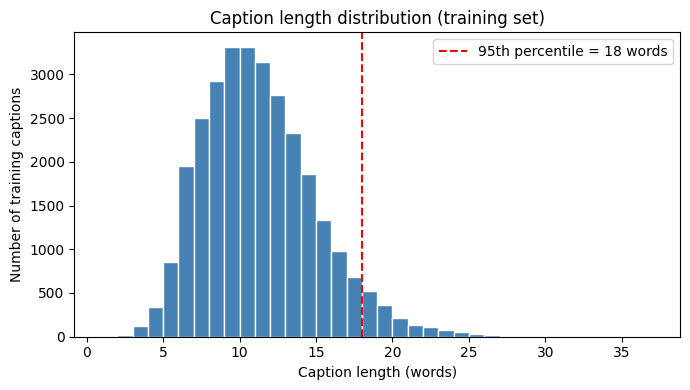

In [2]:
# Figure 1: caption length distribution (training captions)
import re
import numpy as np

def tokenize(caption):
    """Lowercase and keep only words made of letters."""
    return re.findall(r"[a-z]+", caption.lower())

train["tokens"] = train["caption"].apply(tokenize)
train["length"] = train["tokens"].str.len()
lengths = train["length"]

p95 = int(np.percentile(lengths, 95))
p99 = int(np.percentile(lengths, 99))
print(f"Mean {lengths.mean():.1f}, median {lengths.median():.0f}, "
      f"min {lengths.min()}, max {lengths.max()} words")
print(f"95th percentile: {p95} words, 99th percentile: {p99} words")
print(f"Captions longer than {p95} words: {(lengths > p95).mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lengths, bins=range(1, lengths.max() + 2), color="steelblue", edgecolor="white")
ax.axvline(p95, color="red", linestyle="--", label=f"95th percentile = {p95} words")
ax.set_xlabel("Caption length (words)")
ax.set_ylabel("Number of training captions")
ax.set_title("Caption length distribution (training set)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_caption_lengths.png", dpi=200)
plt.show()

Total word tokens: 324339
Distinct words: 7333
Words appearing at least 5 times (kept): 2529
Words appearing fewer than 5 times: 4804 (65.5% of distinct words)
...but they make up only 2.47% of all word tokens
Top 20 words: [('a', 46784), ('in', 14094), ('the', 13509), ('on', 8007), ('is', 6907), ('and', 6678), ('dog', 6160), ('with', 5763), ('man', 5383), ('of', 4974), ('two', 4250), ('white', 2932), ('black', 2865), ('boy', 2634), ('are', 2619), ('woman', 2543), ('girl', 2414), ('to', 2306), ('wearing', 2271), ('at', 2102)]


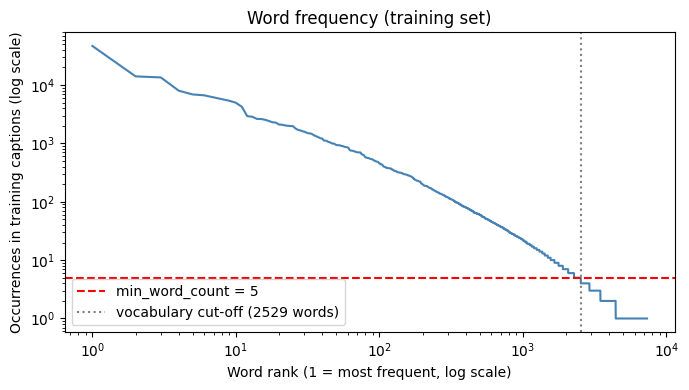

In [3]:
# Figure 2: word frequency (training captions)
from collections import Counter

word_counts = Counter(w for tokens in train["tokens"] for w in tokens)
total_tokens = sum(word_counts.values())
min_count = cfg["vocab"]["min_word_count"]

kept = [w for w, c in word_counts.items() if c >= min_count]
rare_words = len(word_counts) - len(kept)
rare_tokens = sum(c for c in word_counts.values() if c < min_count)

print(f"Total word tokens: {total_tokens}")
print(f"Distinct words: {len(word_counts)}")
print(f"Words appearing at least {min_count} times (kept): {len(kept)}")
print(f"Words appearing fewer than {min_count} times: {rare_words} "
      f"({rare_words / len(word_counts) * 100:.1f}% of distinct words)")
print(f"...but they make up only {rare_tokens / total_tokens * 100:.2f}% of all word tokens")
print("Top 20 words:", word_counts.most_common(20))

counts_sorted = sorted(word_counts.values(), reverse=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(range(1, len(counts_sorted) + 1), counts_sorted, color="steelblue")
ax.axhline(min_count, color="red", linestyle="--",
           label=f"min_word_count = {min_count}")
ax.axvline(len(kept), color="grey", linestyle=":",
           label=f"vocabulary cut-off ({len(kept)} words)")
ax.set_xlabel("Word rank (1 = most frequent, log scale)")
ax.set_ylabel("Occurrences in training captions (log scale)")
ax.set_title("Word frequency (training set)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_word_frequency.png", dpi=200)
plt.show()

Training images: 6000
Median width 500, median height 375
Near-square (aspect 0.9 to 1.1): 4.9%
Squashed by more than 30% when resized to a square: 85.6%


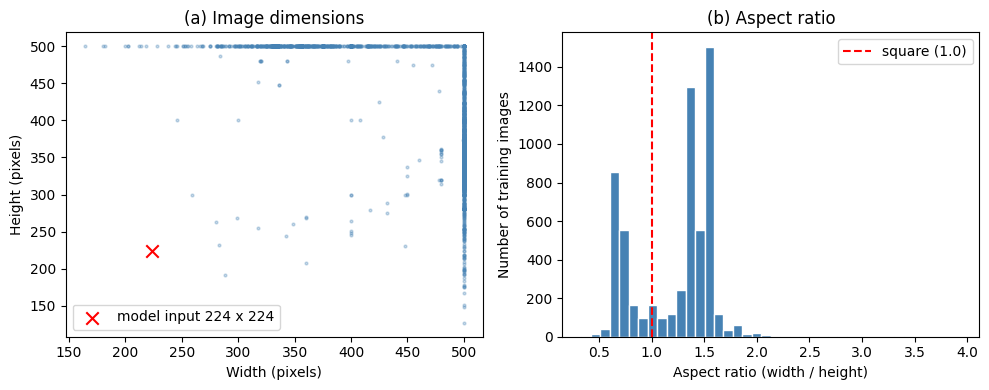

In [4]:
# Figure 3: image dimensions and aspect ratio (training images)
from PIL import Image

image_dir = Path(cfg["paths"]["raw_images"])
train_images = train["image"].drop_duplicates().tolist()
sizes = []
for name in train_images:
    with Image.open(image_dir / name) as img:   # reads only the header, so this is fast
        sizes.append(img.size)

img_df = pd.DataFrame(sizes, columns=["width", "height"], index=train_images)
img_df["aspect"] = img_df["width"] / img_df["height"]

near_square = img_df["aspect"].between(0.9, 1.1).mean() * 100
strongly_squashed = ((img_df["aspect"] > 1.3) | (img_df["aspect"] < 1 / 1.3)).mean() * 100
print(f"Training images: {len(img_df)}")
print(f"Median width {img_df['width'].median():.0f}, median height {img_df['height'].median():.0f}")
print(f"Near-square (aspect 0.9 to 1.1): {near_square:.1f}%")
print(f"Squashed by more than 30% when resized to a square: {strongly_squashed:.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.scatter(img_df["width"], img_df["height"], s=4, alpha=0.3, color="steelblue")
ax1.scatter([224], [224], color="red", marker="x", s=80, label="model input 224 x 224")
ax1.set_xlabel("Width (pixels)")
ax1.set_ylabel("Height (pixels)")
ax1.set_title("(a) Image dimensions")
ax1.legend()

ax2.hist(img_df["aspect"], bins=40, color="steelblue", edgecolor="white")
ax2.axvline(1.0, color="red", linestyle="--", label="square (1.0)")
ax2.set_xlabel("Aspect ratio (width / height)")
ax2.set_ylabel("Number of training images")
ax2.set_title("(b) Aspect ratio")
ax2.legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_image_sizes.png", dpi=200)
plt.show()

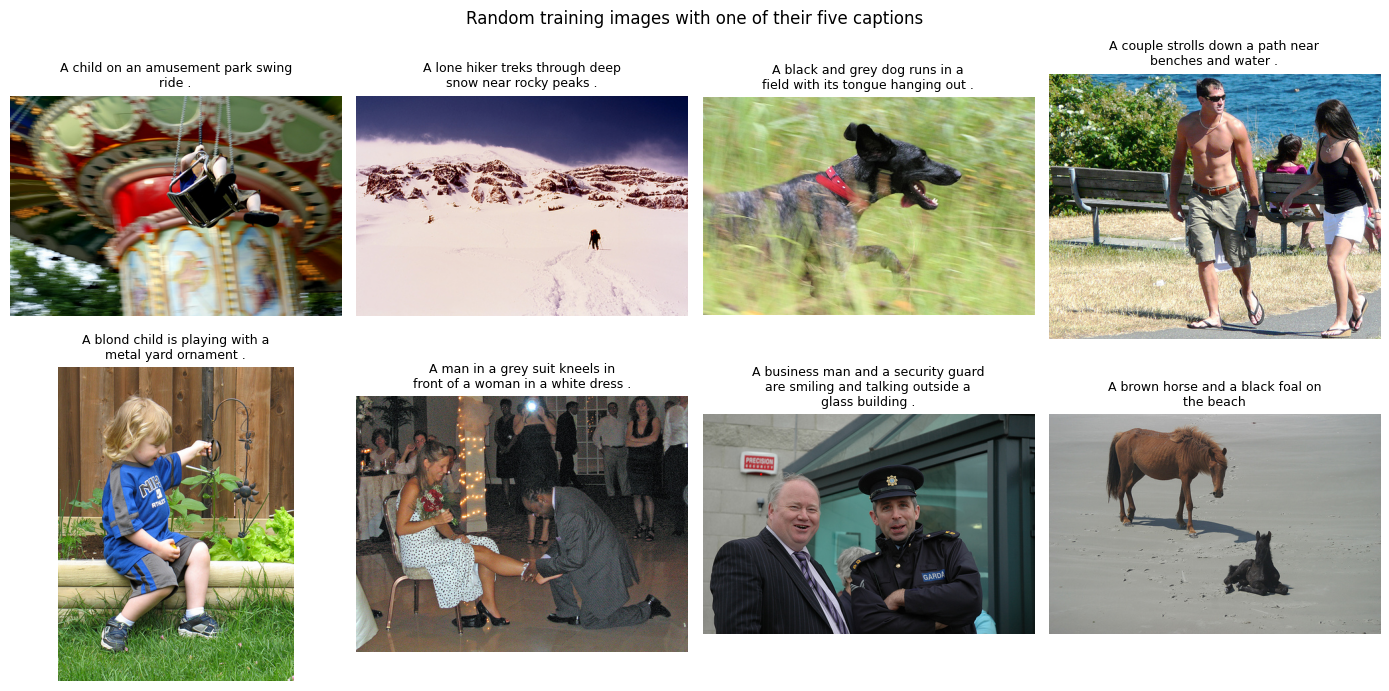

In [5]:
# Figure 4: random training examples with one caption each
import textwrap

examples = (train.drop_duplicates("image")
            .sample(n=8, random_state=cfg.get("seed", 42)))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    with Image.open(image_dir / row["image"]) as img:
        ax.imshow(img)
    ax.set_title("\n".join(textwrap.wrap(row["caption"], 35)), fontsize=9)
    ax.axis("off")

fig.suptitle("Random training images with one of their five captions", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_examples.png", dpi=200)
plt.show()

Distinct 3-word openings: 9078
Top 15 openings cover 19.4% of all training captions
Most common opening: 'a group of' (2.4% of captions)

Share of training images with at least one caption containing the word:
  dog      22.7%
  man      30.3%
  woman    15.4%
  boy      15.4%
  girl     14.0%
  people   15.5%
  water    13.2%
  grass    10.2%


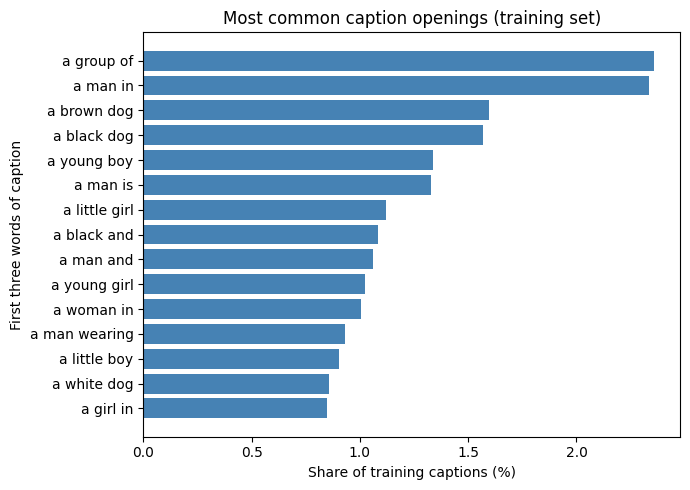

In [6]:
# Figure 5: language shortcuts - most common caption openings (training set)
openings = train["tokens"].apply(lambda t: " ".join(t[:3]))
top = openings.value_counts().head(15)
share = top / len(train) * 100

print(f"Distinct 3-word openings: {openings.nunique()}")
print(f"Top 15 openings cover {share.sum():.1f}% of all training captions")
print(f"Most common opening: '{top.index[0]}' ({share.iloc[0]:.1f}% of captions)")

print("\nShare of training images with at least one caption containing the word:")
for word in ["dog", "man", "woman", "boy", "girl", "people", "water", "grass"]:
    has_word = train.groupby("image")["tokens"].apply(
        lambda caps: any(word in tokens for tokens in caps))
    print(f"  {word:7s} {has_word.mean() * 100:5.1f}%")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(share.index[::-1], share.values[::-1], color="steelblue")
ax.set_xlabel("Share of training captions (%)")
ax.set_ylabel("First three words of caption")
ax.set_title("Most common caption openings (training set)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_caption_openings.png", dpi=200)
plt.show()

Share of captions (%) containing at least one gendered word:
        male  female  ratio male:female
split                                  
train  33.15   20.43               1.62
val    32.14   22.12               1.45
test   34.44   19.92               1.73


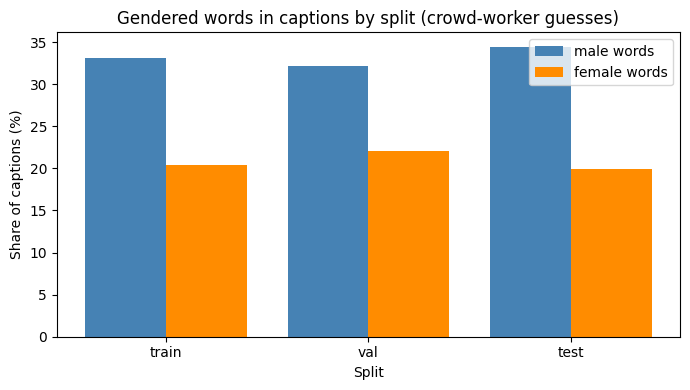

In [7]:
# Figure 6: gendered words in captions, per split (crowd-worker guesses, not real attributes)
male_words = {"man", "men", "boy", "boys", "he", "his", "him", "guy", "guys",
              "gentleman", "father", "son", "husband"}
female_words = {"woman", "women", "girl", "girls", "she", "her", "lady", "ladies",
                "mother", "daughter", "wife"}

df["tokens"] = df["caption"].apply(tokenize)
df["male"] = df["tokens"].apply(lambda t: bool(male_words & set(t)))
df["female"] = df["tokens"].apply(lambda t: bool(female_words & set(t)))

summary = df.groupby("split")[["male", "female"]].mean() * 100
summary = summary.loc[["train", "val", "test"]]
summary["ratio male:female"] = summary["male"] / summary["female"]
print("Share of captions (%) containing at least one gendered word:")
print(summary.round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(summary))
ax.bar(x - 0.2, summary["male"], width=0.4, label="male words", color="steelblue")
ax.bar(x + 0.2, summary["female"], width=0.4, label="female words", color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_xlabel("Split")
ax.set_ylabel("Share of captions (%)")
ax.set_title("Gendered words in captions by split (crowd-worker guesses)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_gender_words.png", dpi=200)
plt.show()

In [8]:
# Pixel intensity check (sample of 500 training images, resized to 224 x 224)
rng = np.random.default_rng(cfg.get("seed", 42))
sample_names = rng.choice(train_images, size=500, replace=False)

pixels = []
for name in sample_names:
    with Image.open(image_dir / name) as img:
        arr = np.asarray(img.resize((224, 224)), dtype=np.float32) / 255.0
    pixels.append(arr)
pixels = np.stack(pixels)   # shape (500, 224, 224, 3)

mean = pixels.mean(axis=(0, 1, 2))
std = pixels.std(axis=(0, 1, 2))
brightness = pixels.mean(axis=(1, 2, 3))

print("Flickr8k training sample (R, G, B):")
print(f"  mean {np.round(mean, 3)}   std {np.round(std, 3)}")
print("ImageNet standard (R, G, B):")
print("  mean [0.485 0.456 0.406]   std [0.229 0.224 0.225]")
print(f"Very dark images (average brightness < 0.15): {(brightness < 0.15).sum()} of 500")
print(f"Very bright images (average brightness > 0.85): {(brightness > 0.85).sum()} of 500")

Flickr8k training sample (R, G, B):
  mean [0.449 0.438 0.394]   std [0.267 0.261 0.277]
ImageNet standard (R, G, B):
  mean [0.485 0.456 0.406]   std [0.229 0.224 0.225]
Very dark images (average brightness < 0.15): 8 of 500
Very bright images (average brightness > 0.85): 0 of 500
